# 02. Mô hình CNN, CRNN và kiểm tra lỗi (debug)
Nhánh GitHub: `02-model-debug`

In [ ]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Mounted at /content/drive
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.6 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [ ]:
meta, X, X_DEV, y, folds = load_data()

  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


## 4. Mô hình
- **CNN:** 4 khối (2 × Conv3×3-BN-ReLU + MaxPool), 32→64→128→256 kênh, trung bình theo tần số, max + mean theo thời gian, Dropout 0,3, FC 50.
- **CRNN:** 4 khối tích chập (2 khối cuối chỉ pooling tần số), Bi-GRU 128, trung bình theo thời gian, Dropout, FC 50.

In [ ]:
n_frames = TARGET_LEN // CFG["HOP_LENGTH"] + 1
for name in ("cnn", "crnn"):
    for n in (64, 128):
        m = build_model(name, n).to(DEVICE).eval()
        with torch.no_grad():
            out = m(torch.randn(2, 1, n, n_frames, device=DEVICE))
        print(f"{name.upper():5s} | {n:3d} Mel bins | output {tuple(out.shape)} | {count_params(m):,} tham số")

CNN   |  64 Mel bins | output (2, 50) | 1,185,490 tham số
CNN   | 128 Mel bins | output (2, 50) | 1,185,490 tham số
CRNN  |  64 Mel bins | output (2, 50) | 2,071,762 tham số
CRNN  | 128 Mel bins | output (2, 50) | 2,858,194 tham số


## 5.1. Kiểm tra lỗi (debug)
Chạy lần lượt A, B, C, D1, D2, D3. D4 (tiền xử lý PANNs) nằm ở notebook E9.

### A. Data loader

A1. Chia tập OK cho mọi fold (không trùng mẫu, đủ 50 lớp). Ví dụ test fold 1: train 1200 | val 400 | test 400
A2. Đọc lại 5 file ngẫu nhiên để so với dữ liệu trong bộ nhớ:
    #405: 2-102414-C-17.wav | nhãn 17 = pouring_water | âm thanh khớp: True | nhãn khớp: True
    #1190: 3-95695-B-5.wav | nhãn 5 = cat | âm thanh khớp: True | nhãn khớp: True
    #1132: 3-197408-A-8.wav | nhãn 8 = sheep | âm thanh khớp: True | nhãn khớp: True
    #731: 2-78781-A-47.wav | nhãn 47 = airplane | âm thanh khớp: True | nhãn khớp: True
    #1754: 5-201664-A-18.wav | nhãn 18 = toilet_flush | âm thanh khớp: True | nhãn khớp: True
A3. Một batch từ data loader:
    wav (32, 110250) torch.float32 trên cuda:0 | nhãn (32,) torch.int64
    biên độ: min -1.048, max 1.081, std 0.1133
A4. Loader duyệt đủ mẫu đúng một lần; train có xáo trộn, val không xáo trộn: OK
A5. Log-Mel chuẩn hóa (32, 1, 64, 216): trung bình 0.144 (≈ 0), độ lệch chuẩn 1.002 (≈ 1)


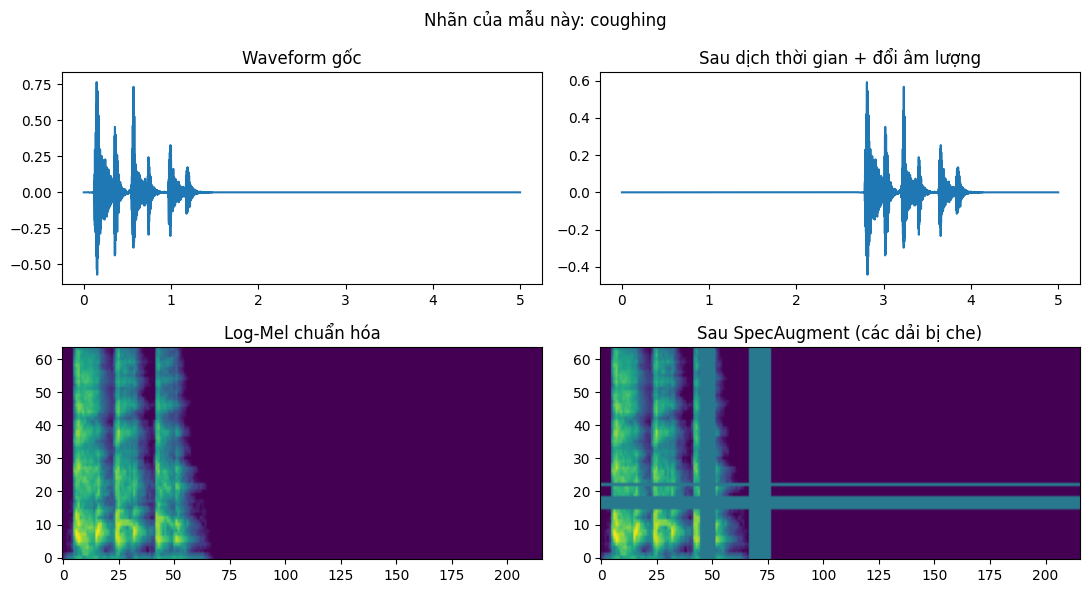

A6. Augmentation giữ nguyên kích thước (xem hình). KẾT LUẬN A: data loader đúng.


In [ ]:
def debug_data_loader():
    y_np = y.numpy()
    cat_of = dict(zip(meta["target"], meta["category"]))
    seq_len = CFG["SAMPLE_RATE"] * CFG["DURATION"]

    for tf in FOLDS:
        tr, va, te = get_split(tf)
        assert not (set(tr) & set(va)) and not (set(tr) & set(te)) and not (set(va) & set(te)), f"fold {tf}: các tập trùng nhau"
        assert len(tr) + len(va) + len(te) == len(X)
        assert set(folds[te]) == {tf} and set(folds[va]) == {tf % 5 + 1}
        assert all(len(np.unique(y_np[s])) == CFG["NUM_CLASSES"] for s in (tr, va, te))
    tr, va, te = get_split(1)
    print(f"A1. Chia tập OK cho mọi fold (không trùng mẫu, đủ 50 lớp). Ví dụ test fold 1: train {len(tr)} | val {len(va)} | test {len(te)}")

    print("A2. Đọc lại 5 file ngẫu nhiên để so với dữ liệu trong bộ nhớ:")
    for i in np.random.RandomState(0).choice(len(X), 5, replace=False):
        same = torch.allclose(load_wave(audio_dir / meta["filename"][i]), X[i].cpu())
        ok = int(y[i]) == int(meta["target"][i])
        print(f"    #{i}: {meta['filename'][i]} | nhãn {int(y[i])} = {meta['category'][i]} | âm thanh khớp: {same} | nhãn khớp: {ok}")
        assert same and ok

    wav, yb = next(iter(make_loader(tr, 32, True)))
    print("A3. Một batch từ data loader:")
    print(f"    wav {tuple(wav.shape)} {wav.dtype} trên {wav.device} | nhãn {tuple(yb.shape)} {yb.dtype}")
    print(f"    biên độ: min {wav.min().item():.3f}, max {wav.max().item():.3f}, std {wav.std().item():.4f}")
    assert tuple(wav.shape) == (32, seq_len) and tuple(yb.shape) == (32,)
    assert torch.isfinite(wav).all() and 0 <= int(yb.min()) and int(yb.max()) < CFG["NUM_CLASSES"]

    seen = torch.cat([b for _, b in make_loader(tr, 32, True)])
    assert len(seen) == len(tr) and torch.equal(torch.sort(seen)[0], torch.sort(y[torch.as_tensor(tr)])[0])
    ld = make_loader(tr, 32, True)
    assert not torch.equal(next(iter(ld))[1], next(iter(ld))[1]), "Dữ liệu train không được xáo trộn giữa các epoch"
    ld_val = make_loader(va, 64, False)
    assert torch.equal(next(iter(ld_val))[1], next(iter(ld_val))[1]), "Dữ liệu val phải giữ nguyên thứ tự"
    print("A4. Loader duyệt đủ mẫu đúng một lần; train có xáo trộn, val không xáo trộn: OK")

    frontend = LogMel(64).to(DEVICE)
    mean, std = compute_stats(frontend, tr)
    spec = (frontend(wav.to(DEVICE)) - mean) / std
    print(f"A5. Log-Mel chuẩn hóa {tuple(spec.shape)}: trung bình {spec.mean().item():.3f} (≈ 0), độ lệch chuẩn {spec.std().item():.3f} (≈ 1)")

    aug = base_augment(wav.to(DEVICE), CFG)
    assert aug.shape == wav.shape
    spec_aug = SpecAug(64, CFG["FREQ_MASK_RATIO"], CFG["TIME_MASK_PARAM"], CFG["NUM_MASKS"]).to(DEVICE)(spec)
    assert spec_aug.shape == spec.shape
    t = np.arange(seq_len) / CFG["SAMPLE_RATE"]
    fig, ax = plt.subplots(2, 2, figsize=(11, 6))
    ax[0, 0].plot(t, wav[0].cpu()); ax[0, 0].set_title("Waveform gốc")
    ax[0, 1].plot(t, aug[0].cpu()); ax[0, 1].set_title("Sau dịch thời gian + đổi âm lượng")
    ax[1, 0].imshow(spec[0, 0].cpu(), origin="lower", aspect="auto"); ax[1, 0].set_title("Log-Mel chuẩn hóa")
    ax[1, 1].imshow(spec_aug[0, 0].cpu(), origin="lower", aspect="auto"); ax[1, 1].set_title("Sau SpecAugment (các dải bị che)")
    fig.suptitle(f"Nhãn của mẫu này: {cat_of[int(yb[0])]}")
    plt.tight_layout()
    plt.show()
    print("A6. Augmentation giữ nguyên kích thước (xem hình). KẾT LUẬN A: data loader đúng.")


debug_data_loader()

### B. Input/Output

In [ ]:
def trace_shapes(exp_id, batch=32):
    e = EXPERIMENTS[exp_id]
    frontend = LogMel(e["n_mels"]).to(DEVICE).eval()
    model = build_model(e["model"], e["n_mels"]).to(DEVICE)
    shapes, hooks = [], []

    def add_hook(name, module):
        def hook(_, __, out):
            out = out[0] if isinstance(out, tuple) else out
            shapes.append((name, tuple(out.shape)))
        hooks.append(module.register_forward_hook(hook))

    for name, m in model.named_children():
        if name == "features":
            for k, blk in enumerate(m):
                add_hook(f"features[{k}]", blk)
        else:
            add_hook(name, m)

    wav = X_DEV[:batch].to(DEVICE)
    with torch.no_grad():
        spec = frontend(wav)
        model.train()
        logits = model((spec - spec.mean()) / spec.std())
    for h in hooks:
        h.remove()

    print(f"[{exp_id}] {e['model'].upper()}, {e['n_mels']} Mel bins")
    print(f"    wav {tuple(wav.shape)}  ->  Log-Mel {tuple(spec.shape)}  (B, kênh, Mel bins, khung thời gian)")
    for name, shp in shapes:
        print(f"    {name:<14} -> {shp}")
    print(f"    logits {tuple(logits.shape)}  (B, số lớp)")
    assert tuple(logits.shape) == (batch, CFG["NUM_CLASSES"])
    probs = torch.softmax(logits.float(), dim=1)
    assert torch.allclose(probs.sum(dim=1), torch.ones(batch, device=probs.device), atol=1e-4)
    loss = F.cross_entropy(logits.float(), y[:batch].to(DEVICE)).item()
    print(f"    CrossEntropy lúc khởi tạo: {loss:.3f} (mô hình chưa học với 50 lớp phải cỡ ln(50) = {np.log(50):.3f}; "
          f"nếu lên hàng chục thì có lỗi, ví dụ đưa softmax vào CrossEntropy)")
    assert loss < 15, "Loss khởi tạo quá lớn"


for exp_id in ["E1", "E2", "E5", "E6"]:
    trace_shapes(exp_id)
print("KẾT LUẬN B: kích thước vào/ra đúng ở mọi lớp; đầu ra là logits (không qua softmax) đúng với CrossEntropyLoss.")

[E1] CNN, 64 Mel bins
    wav (32, 110250)  ->  Log-Mel (32, 1, 64, 216)  (B, kênh, Mel bins, khung thời gian)
    features[0]    -> (32, 32, 32, 108)
    features[1]    -> (32, 64, 16, 54)
    features[2]    -> (32, 128, 8, 27)
    features[3]    -> (32, 256, 4, 13)
    drop           -> (32, 256)
    fc             -> (32, 50)
    logits (32, 50)  (B, số lớp)
    CrossEntropy lúc khởi tạo: 6.116 (mô hình chưa học với 50 lớp phải cỡ ln(50) = 3.912; nếu lên hàng chục thì có lỗi, ví dụ đưa softmax vào CrossEntropy)
[E2] CNN, 128 Mel bins
    wav (32, 110250)  ->  Log-Mel (32, 1, 128, 216)  (B, kênh, Mel bins, khung thời gian)
    features[0]    -> (32, 32, 64, 108)
    features[1]    -> (32, 64, 32, 54)
    features[2]    -> (32, 128, 16, 27)
    features[3]    -> (32, 256, 8, 13)
    drop           -> (32, 256)
    fc             -> (32, 50)
    logits (32, 50)  (B, số lớp)
    CrossEntropy lúc khởi tạo: 6.276 (mô hình chưa học với 50 lớp phải cỡ ln(50) = 3.912; nếu lên hàng chục thì c

### C. Huấn luyện

In [ ]:
def debug_training():
    seq_tr = get_split(1)[0]
    te_idx = get_split(1)[2]

    model = build_model("cnn", 64).to(DEVICE)
    n_all = sum(p.numel() for p in model.parameters())
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"C1. Tham số: {n_all:,} | cập nhật được: {n_train:,} -> "
          f"{'không có lớp bị đóng băng' if n_all == n_train else 'CÓ LỚP BỊ ĐÓNG BĂNG!'}")
    print(f"    model.training: sau train() = {model.train().training}, sau eval() = {model.eval().training}")

    frontend = LogMel(64).to(DEVICE)
    mean, std = compute_stats(frontend, seq_tr)
    wav, yb = next(iter(make_loader(seq_tr, 32, True)))
    wav, yb = wav.to(DEVICE), yb.to(DEVICE)
    with torch.no_grad():
        spec = (frontend(wav) - mean) / std
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"])
    loss = F.cross_entropy(model(spec), yb, label_smoothing=CFG["LABEL_SMOOTHING"])
    opt.zero_grad(set_to_none=True)
    loss.backward()
    norms = {n: (p.grad.norm().item() if p.grad is not None else 0.0) for n, p in model.named_parameters()}
    dead = [n for n, g in norms.items() if g == 0.0]
    nan_ = [n for n, p in model.named_parameters() if p.grad is not None and not torch.isfinite(p.grad).all()]
    total = sum(g ** 2 for g in norms.values()) ** 0.5
    print(f"C2. loss {loss.item():.3f} | lớp không nhận gradient: {dead or 'không có'} | gradient NaN/Inf: {nan_ or 'không có'}")
    print(f"    gradient norm toàn mạng {total:.3f}; từng lớp từ {min(norms.values()):.2e} đến {max(norms.values()):.2e} "
          f"(nếu lên hàng trăm trở lên thì cân nhắc gradient clipping)")
    assert not dead and not nan_

    y_np = y.numpy()
    small = np.concatenate([np.where(y_np == c)[0][:2] for c in range(CFG["NUM_CLASSES"])])
    cfg_small = {**CFG, "EPOCHS": 40, "PATIENCE": 40, "BASE_AUG": False, "MIXUP_ALPHA": 0.0}
    out = train_model("cnn", 64, False, small, small, cfg_small, verbose=False, desc="overfit 100 clip")
    hist = out["history"]
    best_acc = max(h["val_acc"] for h in hist)
    print(f"C3. Overfit 100 clip: loss {hist[0]['loss']:.3f} -> {hist[-1]['loss']:.3f} | độ chính xác cao nhất (trên chính tập này) {best_acc:.2%}")
    print("    " + ("OK: mô hình đủ khả năng học." if best_acc >= 0.9 else
                    "CẢNH BÁO: không học thuộc nổi 100 clip, kiểm tra lại mô hình, learning rate hoặc nhãn."))

    run = lambda: predict(out["model"], out["frontend"], out["mean"], out["std"], make_loader(te_idx, 64, False))[1]
    assert np.array_equal(run(), run())
    print("C4. Hai lần dự đoán liên tiếp cho kết quả giống hệt: OK. KẾT LUẬN C: quy trình huấn luyện đúng.")


debug_training()

C1. Tham số: 1,185,490 | cập nhật được: 1,185,490 -> không có lớp bị đóng băng
    model.training: sau train() = True, sau eval() = False
C2. loss 5.703 | lớp không nhận gradient: không có | gradient NaN/Inf: không có
    gradient norm toàn mạng 26.125; từng lớp từ 5.68e-02 đến 1.23e+01 (nếu lên hàng trăm trở lên thì cân nhắc gradient clipping)


overfit 100 clip:   0%|          | 0/40 [00:00<?, ?it/s]

C3. Overfit 100 clip: loss 4.905 -> 1.380 | độ chính xác cao nhất (trên chính tập này) 99.00%
    OK: mô hình đủ khả năng học.
C4. Hai lần dự đoán liên tiếp cho kết quả giống hệt: OK. KẾT LUẬN C: quy trình huấn luyện đúng.


### D1. Dữ liệu và chuẩn hóa

In [ ]:
def debug_dataset():
    from IPython.display import Audio, display
    y_np = y.numpy()
    tr, va, te = get_split(1)

    r = torch.randn(X.shape[1], dtype=torch.float64, generator=torch.Generator().manual_seed(0))
    sig_all = torch.cat([X[k:k + 200].double() @ r for k in range(0, len(X), 200)])

    print("D1.1 Ba batch đầu của data loader (có xáo trộn):")
    prev = None
    for k, (wav, yb) in enumerate(make_loader(tr, 32, True)):
        if k == 3:
            break
        w = wav.cpu()
        print(f"    batch {k}: wav {tuple(w.shape)} | std {w.std().item():.4f} | mẫu toàn số 0: {(w.abs().amax(dim=1) == 0).sum().item()} "
              f"| số lớp khác nhau: {len(yb.unique())}/32 | 6 nhãn đầu: {yb[:6].tolist()}")
        assert w.abs().max() > 0, "Batch toàn số 0"
        sigs = w.double() @ r
        idx = torch.argmin((sig_all[None, :] - sigs[:, None]).abs(), dim=1)
        assert torch.allclose(sig_all[idx], sigs, atol=1e-6), "Không truy ngược được mẫu trong batch"
        assert torch.equal(y[idx], yb), "Nhãn LỆCH với âm thanh sau khi xáo trộn!"
        assert prev is None or not torch.equal(prev, sigs), "Hai batch liên tiếp giống hệt nhau"
        assert set(folds[idx.numpy()]) <= set(folds[tr]), "Batch train chứa mẫu ngoài tập train"
        prev = sigs
    print("D1.2 Âm thanh và nhãn đi cùng nhau sau khi xáo trộn, hai batch khác nhau, không lẫn mẫu val/test vào train: OK")

    print(f"D1.3 32 mẫu đầu theo thứ tự gốc có {len(set(y_np[:32].tolist()))} lớp khác nhau")
    uniq = [len(b.unique()) for _, b in make_loader(tr, 32, True) if len(b) == 32]
    print(f"     số lớp trong mỗi batch 32 mẫu khi xáo trộn: nhỏ nhất {min(uniq)}, trung bình {np.mean(uniq):.1f}")
    assert len(set(y_np[:32].tolist())) > 1 and min(uniq) >= 12

    for name, idx in (("train", tr), ("val", va), ("test", te)):
        c = np.bincount(y_np[idx], minlength=CFG["NUM_CLASSES"])
        print(f"D1.4 {name}: {len(idx)} clip, mỗi lớp từ {c.min()} đến {c.max()} clip")
        assert c.min() == c.max(), f"Tập {name} mất cân bằng lớp"
    print(f"     Lưu ý: chỉ có {len(tr) // CFG['NUM_CLASSES']} clip/lớp để huấn luyện (huấn luyện từ đầu thường cần nhiều hơn), "
          "đó là lý do dùng augmentation, Mixup và mô hình pretrain E9.")

    frontend = LogMel(64).to(DEVICE)
    m_tr, s_tr = compute_stats(frontend, tr)
    m_all, s_all = compute_stats(frontend, np.arange(len(X)))
    print(f"D1.5 Chuẩn hóa: mean/std chỉ trên train = {m_tr:.3f}/{s_tr:.3f} | trên toàn bộ dữ liệu (cách SAI) = {m_all:.3f}/{s_all:.3f}")
    try:
        import inspect
        assert "compute_stats(frontend, train_idx)" in inspect.getsource(train_model)
        print("     train_model chỉ tính thống kê trên train_idx: OK")
    except (OSError, TypeError):
        print("     (không đọc được mã nguồn train_model để kiểm tra tự động)")
    with torch.no_grad():
        v = (frontend(X_DEV[torch.as_tensor(va)[:64].to(X_DEV.device)].to(DEVICE)) - m_tr) / s_tr
    print(f"     val sau khi chuẩn hóa bằng thống kê của train: mean {v.mean().item():.3f}, std {v.std().item():.3f} (gần 0 và 1, không cần đúng tuyệt đối)")

    print("D1.6 Nghe thử 6 clip ngẫu nhiên và so với nhãn:")
    for i in np.random.RandomState(1).choice(len(X), 6, replace=False):
        print(f"    {meta['filename'][i]}: {meta['category'][i]} ({VI_LIST[int(y[i])]})")
        display(Audio(X[i].numpy(), rate=SR))


debug_dataset()

D1.1 Ba batch đầu của data loader (có xáo trộn):
    batch 0: wav (32, 110250) | std 0.0971 | mẫu toàn số 0: 0 | số lớp khác nhau: 25/32 | 6 nhãn đầu: [14, 10, 42, 34, 41, 4]
    batch 1: wav (32, 110250) | std 0.1507 | mẫu toàn số 0: 0 | số lớp khác nhau: 28/32 | 6 nhãn đầu: [12, 3, 23, 2, 38, 26]
    batch 2: wav (32, 110250) | std 0.1105 | mẫu toàn số 0: 0 | số lớp khác nhau: 22/32 | 6 nhãn đầu: [11, 11, 47, 0, 9, 30]
D1.2 Âm thanh và nhãn đi cùng nhau sau khi xáo trộn, hai batch khác nhau, không lẫn mẫu val/test vào train: OK
D1.3 32 mẫu đầu theo thứ tự gốc có 16 lớp khác nhau
     số lớp trong mỗi batch 32 mẫu khi xáo trộn: nhỏ nhất 21, trung bình 24.2
D1.4 train: 1200 clip, mỗi lớp từ 24 đến 24 clip
D1.4 val: 400 clip, mỗi lớp từ 8 đến 8 clip
D1.4 test: 400 clip, mỗi lớp từ 8 đến 8 clip
     Lưu ý: chỉ có 24 clip/lớp để huấn luyện (huấn luyện từ đầu thường cần nhiều hơn), đó là lý do dùng augmentation, Mixup và mô hình pretrain E9.
D1.5 Chuẩn hóa: mean/std chỉ trên train = -12.13

    5-191497-A-33.wav: door_wood_creaks (Cửa gỗ kẽo kẹt)


    4-155670-A-26.wav: laughing (Cười)


    4-163609-B-16.wav: wind (Gió)


    4-117627-A-25.wav: footsteps (Bước chân)


    5-160614-F-48.wav: fireworks (Pháo hoa)


### D2. Đầu vào ngẫu nhiên

In [ ]:
def debug_random_input(epochs=6):
    tr, va, _ = get_split(1)
    frontend = LogMel(64).to(DEVICE)
    mean, std = compute_stats(frontend, tr)

    def run(real):
        set_seed(CFG["SEED"])
        model = build_model("cnn", 64).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
        hist = []
        for ep in range(epochs):
            model.train()
            losses = []
            for wav, yb in make_loader(tr, 32, True):
                wav, yb = wav.to(DEVICE), yb.to(DEVICE)
                if not real:
                    wav = torch.randn_like(wav) * wav.std()
                with torch.no_grad():
                    x = (frontend(wav) - mean) / std
                loss = F.cross_entropy(model(x), yb)
                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()
                losses.append(loss.item())
            model.eval()
            correct = 0
            with torch.no_grad():
                for wav, yb in make_loader(va, 64, False):
                    wav, yb = wav.to(DEVICE), yb.to(DEVICE)
                    if not real:
                        wav = torch.randn_like(wav) * wav.std()
                    correct += (model((frontend(wav) - mean) / std).argmax(1) == yb).sum().item()
            hist.append((float(np.mean(losses)), correct / len(va)))
        return hist

    real_h, rand_h = run(True), run(False)
    rows = [dict(epoch=e + 1, loss_thật=round(real_h[e][0], 3), acc_thật=f"{real_h[e][1]:.1%}",
                 loss_nhiễu=round(rand_h[e][0], 3), acc_nhiễu=f"{rand_h[e][1]:.1%}") for e in range(epochs)]
    display(pd.DataFrame(rows).set_index("epoch"))
    print(f"Đầu vào nhiễu: loss cuối {rand_h[-1][0]:.3f} (≈ ln(50) = {np.log(50):.3f}, không học được), "
          f"độ chính xác {rand_h[-1][1]:.1%} (≈ 2% ngẫu nhiên). Đầu vào thật: {real_h[-1][1]:.1%}.")
    ok = rand_h[-1][1] < 0.10 and real_h[-1][1] > rand_h[-1][1] + 0.1
    print("KẾT LUẬN D2:", "đúng như kỳ vọng, nhãn không rò rỉ và dữ liệu thật mới học được." if ok else
          "CẢNH BÁO: kết quả bất thường, kiểm tra lại đường dẫn dữ liệu và nhãn.")


debug_random_input()

,loss_thật,acc_thật,loss_nhiễu,acc_nhiễu
epoch,,,,
1,3.818,7.2%,4.206,2.0%
2,3.033,16.0%,4.072,2.0%
3,2.560,27.0%,4.082,2.0%
4,2.246,35.8%,4.037,2.0%
5,1.925,38.5%,4.041,2.0%
6,1.650,36.8%,4.013,2.0%


Đầu vào nhiễu: loss cuối 4.013 (≈ ln(50) = 3.912, không học được), độ chính xác 2.0% (≈ 2% ngẫu nhiên). Đầu vào thật: 36.8%.
KẾT LUẬN D2: đúng như kỳ vọng, nhãn không rò rỉ và dữ liệu thật mới học được.


### D3. Mức augmentation

In [ ]:
def debug_augmentation_strength(epochs=30):
    tr, va, _ = get_split(1)
    sub = tr[np.random.RandomState(0).choice(len(tr), 400, replace=False)]
    settings = [
        ("Không augmentation", dict(BASE_AUG=False, MIXUP_ALPHA=0.0), False),
        ("+ Dịch thời gian, đổi âm lượng", dict(BASE_AUG=True, MIXUP_ALPHA=0.0), False),
        ("+ SpecAugment", dict(BASE_AUG=True, MIXUP_ALPHA=0.0), True),
        ("+ SpecAugment + Mixup", dict(BASE_AUG=True, MIXUP_ALPHA=CFG["MIXUP_ALPHA"] or 0.4), True),
    ]
    rows = []
    for name, over, sa in settings:
        cfg = {**CFG, **over, "EPOCHS": epochs, "PATIENCE": epochs}
        out = train_model("cnn", 64, sa, tr, va, cfg, verbose=False, desc=name)
        m = (out["model"], out["frontend"], out["mean"], out["std"])
        tr_acc = scores(*predict(*m, make_loader(sub, 64, False)))[0]
        va_acc = scores(*predict(*m, make_loader(va, 64, False)))[0]
        rows.append({"Mức augmentation": name, "Acc train (sạch)": f"{tr_acc:.1%}", "Acc validation": f"{va_acc:.1%}",
                     "Chênh lệch": f"{(tr_acc - va_acc) * 100:.1f} điểm"})
    display(pd.DataFrame(rows).set_index("Mức augmentation"))
    print("Cách đọc: acc train thấp (dưới khoảng 80%) kèm validation thấp là dấu hiệu học thiếu do augmentation/regularization quá nhiều; "
          "acc train gần 100% mà validation thấp hơn nhiều là quá khớp (cần thêm augmentation).")


debug_augmentation_strength()

Không augmentation:   0%|          | 0/30 [00:00<?, ?it/s]

+ Dịch thời gian, đổi âm lượng:   0%|          | 0/30 [00:00<?, ?it/s]

+ SpecAugment:   0%|          | 0/30 [00:00<?, ?it/s]

+ SpecAugment + Mixup:   0%|          | 0/30 [00:00<?, ?it/s]

,Acc train (sạch),Acc validation,Chênh lệch
Mức augmentation,,,
Không augmentation,100.0%,81.2%,18.8 điểm
"+ Dịch thời gian, đổi âm lượng",99.2%,81.2%,18.0 điểm
+ SpecAugment,96.8%,78.2%,18.5 điểm
+ SpecAugment + Mixup,96.8%,80.8%,16.0 điểm


Cách đọc: acc train thấp (dưới khoảng 80%) kèm validation thấp là dấu hiệu học thiếu do augmentation/regularization quá nhiều; acc train gần 100% mà validation thấp hơn nhiều là quá khớp (cần thêm augmentation).
